# Which forecast should you trust for Dublin tomorrow?

Isodrome keeps every version of every event with three times: when it **happened** (the hour a
forecast is for), when the source **published** it, and when Isodrome **received** it. That makes
questions like *"what did each model say at 9 a.m. about 3 p.m.?"* exact, and it makes forecast
verification free of look-ahead by construction.

This notebook uses Isodrome's public weather feeds: four forecast models (Met Éireann HARMONIE,
ECMWF IFS and AIFS, DWD ICON-EU, NOAA GFS) and Met Éireann's observations.

**Setup:** `pip install 'isodrome[notebook]'`, then `iso login` once in a terminal.

In [1]:
import isodrome as iso
import pandas as pd

client = iso.connect()   # uses what `iso login` saved
STATION = "dublin-airport"
pd.set_option("display.max_columns", 12)

## 1. What's there

Your own feeds, then other organizations' public ones.

In [2]:
client.feeds(public=True)

,feed,public,key,event time,events,last received,description
0,isodrome/public/dwd_icon_eu_forecast,True,location,valid_time,3906,2026-10-16 09:43:01.679000+00:00,DWD ICON-EU forecasts at points: one event per...
1,isodrome/public/ecmwf_open_data_forecast,True,location,valid_time,13560,2026-10-16 12:34:24.775000+00:00,ECMWF IFS and AIFS forecasts at points: one ev...
2,isodrome/public/geonames_postal_codes,True,id,(arrival),139,2026-10-15 15:19:00.986000+00:00,"Postal codes with place name, administrative a..."
3,isodrome/public/met_eireann_observations,True,station,observed_at,1258017,2026-10-16 14:19:41.889000+00:00,Met Éireann hourly observations: the quality-c...
4,isodrome/public/met_eireann_point_forecast,True,location,valid_to,2664,2026-10-16 09:19:49.292000+00:00,Met Éireann point forecasts: one event per loc...
5,isodrome/public/met_eireann_warnings,True,identifier,starts,19560,2026-10-15 15:36:30.226000+00:00,Met Éireann weather warnings: one event per CA...
6,isodrome/public/noaa_gfs_forecast,True,location,valid_time,52668,2026-10-16 11:19:55.335000+00:00,NOAA GFS forecasts at points: one event per lo...


## 2. One feed: 80 years of Dublin Airport

A feed describes itself: where the data comes from, its licence, and the credit it asks for
(shown under every result too). Choosing columns matters: two columns of 700,000 hours is a
few megabytes.

In [3]:
obs = client.feed("isodrome/public/met_eireann_observations")
obs

feed,isodrome/public/met_eireann_observations
description,Met Éireann hourly observations: the quality-controlled climate archive (source=archive) and live reports (source=live)
source,https://www.met.ie/climate/available-data/historical-data
licence,CC BY 4.0 (Met Éireann open data); attribute the source
attribution,Copyright Met Éireann. Source: www.met.ie. Licence: CC BY 4.0
access,public
events,"1,258,017"
last received,2026-10-16 14:19:41.889000+00:00
newest event time,2026-10-16 14:00:00+00:00
key,station
event time,observed_at


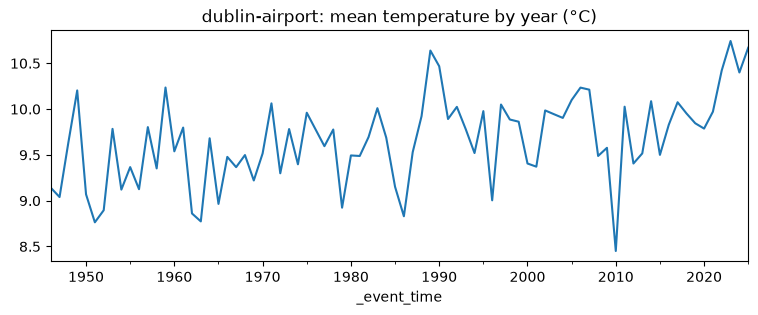

In [4]:
history = obs.query(where={"_key": STATION}, columns=["_event_time", "temperature_c"]).to_df()
yearly = history.set_index("_event_time")["temperature_c"].resample("YE").mean()
yearly[yearly.index.year < pd.Timestamp.now().year].plot(
    title=f"{STATION}: mean temperature by year (°C)", figsize=(9, 3));

## 3. The three clocks

Each model run publishes a new forecast for the same hour, so *the* forecast for an hour is
ambiguous until you say *as of when*. `versions()` shows every version with all three times.

In [5]:
FORECASTS = {   # feed: column with 2 m temperature, and its unit
    "isodrome/public/met_eireann_point_forecast": ("temperature.value", "C"),
    "isodrome/public/ecmwf_open_data_forecast": ("t2m_k", "K"),
    "isodrome/public/dwd_icon_eu_forecast": ("t2m_k", "K"),
    "isodrome/public/noaa_gfs_forecast": ("t2m_k", "K"),
}

def celsius(df, column, unit):
    return df[column] - 273.15 if unit == "K" else df[column]

ecmwf = client.feed("isodrome/public/ecmwf_open_data_forecast")
v = ecmwf.versions(since="2d", where={"_key": STATION, "model": "ifs"}, columns=["model_run", "t2m_k"]).to_df()
hour = v["_event_time"].value_counts().idxmax()   # the hour with the most versions
one = v[v["_event_time"] == hour].sort_values("_published_time")
one.assign(t2m_c=celsius(one, "t2m_k", "K").round(1))[
    ["_event_time", "model_run", "_published_time", "_receive_time", "t2m_c"]]

,_event_time,model_run,_published_time,_receive_time,t2m_c
185,2026-10-16 06:00:00+00:00,2026-10-12T00:00:00Z,2026-10-12 07:34:00+00:00,2026-10-15 15:55:27.370000+00:00,6.5
186,2026-10-16 06:00:00+00:00,2026-10-12T06:00:00Z,2026-10-12 12:27:00+00:00,2026-10-15 16:03:49.270000+00:00,6.5
187,2026-10-16 06:00:00+00:00,2026-10-12T12:00:00Z,2026-10-12 19:34:00+00:00,2026-10-15 16:09:39.538000+00:00,6.3
188,2026-10-16 06:00:00+00:00,2026-10-12T18:00:00Z,2026-10-13 00:27:00+00:00,2026-10-15 16:17:17.121000+00:00,6.4
189,2026-10-16 06:00:00+00:00,2026-10-13T00:00:00Z,2026-10-13 07:34:00+00:00,2026-10-15 16:21:07.533000+00:00,6.7
190,2026-10-16 06:00:00+00:00,2026-10-13T06:00:00Z,2026-10-13 12:27:00+00:00,2026-10-15 16:27:46.112000+00:00,6.2
191,2026-10-16 06:00:00+00:00,2026-10-13T12:00:00Z,2026-10-13 19:34:00+00:00,2026-10-15 16:32:09.228000+00:00,6.3
192,2026-10-16 06:00:00+00:00,2026-10-13T18:00:00Z,2026-10-14 00:27:00+00:00,2026-10-15 16:38:02.191000+00:00,6.5
193,2026-10-16 06:00:00+00:00,2026-10-14T00:00:00Z,2026-10-14 07:34:00+00:00,2026-10-15 16:41:07.280000+00:00,6.3
194,2026-10-16 06:00:00+00:00,2026-10-14T06:00:00Z,2026-10-14 12:27:00+00:00,2026-10-15 16:46:58.040000+00:00,6.5


## 4. As of a moment

What each model said, as published by a given moment, about one hour: one query per model,
`as_of` on the publication basis and one version per hour (the most recently published).

In [6]:
target = hour
moment = target - pd.Timedelta("24h")
rows = []
for name, (column, unit) in FORECASTS.items():
    df = client.feed(name).query(
        where={"_key": STATION}, start=target, end=target + pd.Timedelta("1s"),
        as_of=moment, basis="published",
        dedupe=["_key", "model", "_event_time"], order="publication",
        columns=["_event_time", "_published_time", "model", column],
    ).to_df()
    for _, r in df.iterrows():
        rows.append({"model": r["model"], "published": r["_published_time"],
                     "forecast °C": round(float(celsius(df.loc[[_]], column, unit).iloc[0]), 1)})
print(f"Forecasts for {target:%Y-%m-%d %H:%M} UTC, as published by {moment:%Y-%m-%d %H:%M} UTC")
pd.DataFrame(rows)

Forecasts for 2026-10-16 06:00 UTC, as published by 2026-10-15 06:00 UTC


,model,published,forecast °C
0,ifs,2026-10-15 00:27:00+00:00,6.6
1,aifs-single,2026-10-15 05:54:00+00:00,6.8
2,icon-eu,2026-10-15 03:00:58+00:00,6.8
3,gfs,2026-10-15 03:42:00+00:00,5.8


## 5. Verification, without look-ahead

For every hour, each model's forecast **as it stood 24 hours earlier** (`as_of_lag`), next to what
was then observed. Nothing published later can leak in: that is how the query is defined.

In [7]:
observed = obs.query(since="10d", where={"_key": STATION}, columns=["_event_time", "temperature_c"]).to_df()

def forecasts_at_lead(lead):
    frames = []
    for name, (column, unit) in FORECASTS.items():
        df = client.feed(name).query(
            since="10d", where={"_key": STATION}, as_of_lag=lead, basis="published",
            dedupe=["_key", "model", "_event_time"], order="publication",
            columns=["_event_time", "model", column],
        ).to_df()
        frames.append(df.assign(forecast_c=celsius(df, column, unit))[["_event_time", "model", "forecast_c"]])
    joined = pd.concat(frames).merge(observed, on="_event_time")
    return joined.assign(error=joined["forecast_c"] - joined["temperature_c"])

day_ahead = forecasts_at_lead("24h")
scores = day_ahead.groupby("model")["error"].agg(
    hours="count", mae=lambda e: e.abs().mean(), bias="mean").round(2).sort_values("mae")
scores

,hours,mae,bias
model,,,
harmonie,5,0.40,0.36
icon-eu,18,0.67,-0.58
aifs-single,11,0.68,0.21
gfs,64,0.87,-0.37
ifs,21,0.95,-0.10


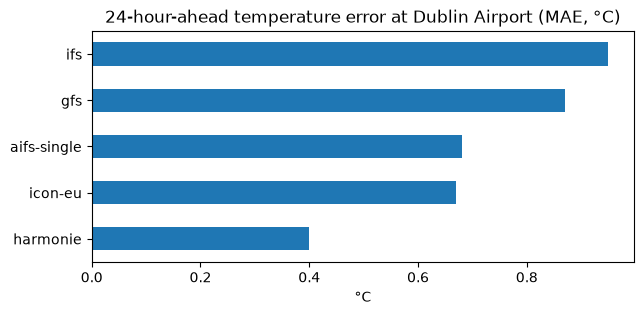

In [8]:
ax = scores["mae"].plot.barh(title="24-hour-ahead temperature error at Dublin Airport (MAE, °C)", figsize=(7, 3))
ax.set_xlabel("°C"); ax.set_ylabel("");

Further ahead, forecasts get worse. The same query with a different `as_of_lag`
(models that have not been running long enough for a lead time have no row yet):

In [9]:
by_lead = pd.DataFrame({
    lead: forecasts_at_lead(lead).groupby("model")["error"].apply(lambda e: e.abs().mean())
    for lead in ["3h", "12h", "24h", "48h"]
}).round(2)
by_lead

,3h,12h,24h,48h
model,,,,
aifs-single,0.48,0.53,0.68,0.57
gfs,0.71,0.80,0.87,0.97
harmonie,0.41,0.54,0.40,NaN
icon-eu,0.78,0.73,0.67,NaN
ifs,0.68,0.76,0.95,1.07


## 6. Exactly the same answer, later

Every result records the position in the feed's log where it was read. Reading at that position
gives exactly the same events, however much has arrived since: results can be cited and
reproduced.

In [10]:
q = obs.query(since="1d", where={"_key": STATION}, columns=["_event_time", "temperature_c"])
first = q.fetch()
print("read at position", first.position, "->", len(first), "events")
again = q.at(first.position).to_df()
print("same events again:", again.equals(first.to_df()))

read at position (1258017,) -> 24 events


same events again: True


## 7. Point-in-time joins

For each row of your own data (trades, decisions, alerts), what a feed said **at that row's
time**: here, for a few moments, the latest observation that had been published by then, and how
old it was.

In [11]:
moments = pd.DataFrame({
    "time": pd.date_range(end=pd.Timestamp.now(tz="UTC").floor("h"), periods=6, freq="3h"),
    "station": STATION,
})
joined = iso.as_of_join(moments, obs.query(since="3d"), at="time", key="station", columns=["temperature_c"])
joined.assign(age=joined["time"] - joined["_event_time"])[["time", "temperature_c", "_event_time", "age"]]

,time,temperature_c,_event_time,age
0,2026-10-15 23:00:00+00:00,10.0,2026-10-15 22:00:00+00:00,0 days 01:00:00
1,2026-10-16 02:00:00+00:00,8.0,2026-10-16 01:00:00+00:00,0 days 01:00:00
2,2026-10-16 05:00:00+00:00,7.0,2026-10-16 04:00:00+00:00,0 days 01:00:00
3,2026-10-16 08:00:00+00:00,7.0,2026-10-16 07:00:00+00:00,0 days 01:00:00
4,2026-10-16 11:00:00+00:00,10.0,2026-10-16 10:00:00+00:00,0 days 01:00:00
5,2026-10-16 14:00:00+00:00,12.0,2026-10-16 13:00:00+00:00,0 days 01:00:00


## 8. Live

`tail` gives the latest events and then new ones as they arrive. In a notebook, `obs.watch()`
shows a table that updates in place (interrupt the kernel to stop it).

In [12]:
for batch in ecmwf.tail(last=3, columns=["_event_time", "_key", "model", "t2m_k"], follow=False):
    display(batch)

,_event_time,_key,model,t2m_k
0,2026-10-31 06:00:00+00:00,dun-laoghaire,aifs-single,280.311829
1,2026-10-31 06:00:00+00:00,howth,aifs-single,282.468079
2,2026-10-31 06:00:00+00:00,tallaght,aifs-single,280.311829
